## Price and Neighborhood

In [1]:
import warnings
from glob import glob    # used to import multiple CSV files at the same time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from category_encoders import OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.pipeline import make_pipeline

# Prepare Data
#### Import Data

In [2]:
def wrangle(filepath):
    # Read CSV file
    df = pd.read_csv(filepath)

    # Subset data: Apartments in "Capital Federal", less than 400,000
    mask_ba = df["place_with_parent_names"].str.contains("Capital Federal")
    mask_apt = df["property_type"] == "apartment"
    mask_price = df["price_aprox_usd"] < 400_000
    df = df[mask_ba & mask_apt & mask_price]

    # Subset data: Remove outliers for "surface_covered_in_m2"
    low, high = df["surface_covered_in_m2"].quantile([0.1, 0.9])
    mask_area = df["surface_covered_in_m2"].between(low, high)
    df = df[mask_area]

    # Split "lat-lon" column
    df[["lat", "lon"]] = df["lat-lon"].str.split(",", expand=True).astype(float)
    df.drop(columns="lat-lon", inplace=True)

    # extracting neighbourhood
    df['neighborhood']= df['place_with_parent_names'].str.split('|',expand=True)[3]
    df.drop(columns='place_with_parent_names',inplace=True)

    

    return df

In [3]:
files= glob(r"C:\Users\Peace\OneDrive\WP projects\HOUSING IN BUENOS AIRES 2\Bueinos-Aires-Real_estate-* - Sheet1.csv")
files

['C:\\Users\\Peace\\OneDrive\\WP projects\\HOUSING IN BUENOS AIRES 2\\Bueinos-Aires-Real_estate-1 - Sheet1.csv',
 'C:\\Users\\Peace\\OneDrive\\WP projects\\HOUSING IN BUENOS AIRES 2\\Bueinos-Aires-Real_estate-2 - Sheet1.csv',
 'C:\\Users\\Peace\\OneDrive\\WP projects\\HOUSING IN BUENOS AIRES 2\\Bueinos-Aires-Real_estate-3 - Sheet1.csv',
 'C:\\Users\\Peace\\OneDrive\\WP projects\\HOUSING IN BUENOS AIRES 2\\Bueinos-Aires-Real_estate-4 - Sheet1.csv',
 'C:\\Users\\Peace\\OneDrive\\WP projects\\HOUSING IN BUENOS AIRES 2\\Bueinos-Aires-Real_estate-5 - Sheet1.csv']

- glob finds files whose names match a pattern, and gives you back a list of their paths. It's like using the search box in File Explorer, but from your code.

Why it's useful in your project

You have several CSV files with similar names (...-1.csv, ...-2.csv, and so on). Instead of typing out each path by hand, you write one pattern that describes all of them, and glob finds them for you. This matters more as the number of files grows, and it means your code still works if you add another file later.

In [4]:
frames=[]
for file in files:
    df= wrangle(file)
    frames.append(df)


In [5]:
type(frames[2])

pandas.core.frame.DataFrame

In [6]:
print(len(frames))

5


the frame list now has 5 dataframes in it. the next thing to do is to concatenate

In [7]:
frames[4].head()

,Unnamed: 0,operation,property_type,price,currency,price_aprox_local_currency,price_aprox_usd,surface_total_in_m2,surface_covered_in_m2,price_usd_per_m2,price_per_m2,floor,rooms,expenses,properati_url,lat,lon,neighborhood
3,4,sell,apartment,112000.0,USD,1698188.80,112000.0,NaN,60.0,NaN,1866.666667,1.0,2.0,NaN,http://belgrano.properati.com.ar/116pr_venta_d...,-34.564676,-58.455720,Belgrano
9,10,sell,apartment,76500.0,USD,1159923.60,76500.0,0.0,36.0,NaN,2125.000000,NaN,2.0,1000.0,http://caballito.properati.com.ar/12ksf_venta_...,-34.618830,-58.437779,Caballito
18,19,sell,apartment,90000.0,USD,1364616.00,90000.0,100.0,100.0,900.000000,900.000000,NaN,3.0,NaN,http://belgrano.properati.com.ar/zouu_venta_de...,-34.577168,-58.538654,Belgrano
20,21,sell,apartment,159900.0,USD,2424467.76,159900.0,82.0,77.0,1950.000000,2076.623377,NaN,3.0,NaN,http://colegiales.properati.com.ar/zpcd_venta_...,-34.571526,-58.455637,Colegiales
21,22,sell,apartment,123875.0,USD,1878242.30,123875.0,79.0,50.0,1568.037975,2477.500000,NaN,2.0,NaN,http://colegiales.properati.com.ar/12sbf_venta...,-34.578688,-58.457358,Colegiales


##### Concateneate the datadrames.

In [8]:
df=pd.concat(frames, ignore_index=True)
df.shape

(6582, 20)

In [9]:
df.head()

,operation,property_type,price,currency,price_aprox_local_currency,price_aprox_usd,surface_total_in_m2,surface_covered_in_m2,price_usd_per_m2,price_per_m2,floor,rooms,expenses,properati_url,index,lat,lon,neighborhood,Index,Unnamed: 0
0,sell,apartment,129000.0,USD,1955949.6,129000.0,76.0,70.0,1697.368421,1842.857143,NaN,NaN,NaN,http://chacarita.properati.com.ar/10qlv_venta_...,5.0,-34.584651,-58.454693,Chacarita,NaN,NaN
1,sell,apartment,87000.0,USD,1319128.8,87000.0,48.0,42.0,1812.500000,2071.428571,NaN,NaN,NaN,http://villa-luro.properati.com.ar/12m82_venta...,10.0,-34.638979,-58.500115,Villa Luro,NaN,NaN
2,sell,apartment,118000.0,USD,1789163.2,118000.0,NaN,54.0,NaN,2185.185185,NaN,2.0,NaN,http://caballito.properati.com.ar/11wqh_venta_...,30.0,-34.615847,-58.459957,Caballito,NaN,NaN
3,sell,apartment,57000.0,USD,864256.8,57000.0,42.0,42.0,1357.142857,1357.142857,5.0,2.0,364,http://constitucion.properati.com.ar/k2f0_vent...,41.0,-34.625222,-58.382382,Constitución,NaN,NaN
4,sell,apartment,90000.0,USD,1364616.0,90000.0,57.0,50.0,1578.947368,1800.000000,NaN,3.0,450,http://once.properati.com.ar/suwa_venta_depart...,42.0,-34.610610,-58.412511,Once,NaN,NaN


In [10]:
df['place_with_parent_names'].str.split('|',expand=True)[3].head()

KeyError: 'place_with_parent_names'

In [11]:
df.head()

,operation,property_type,price,currency,price_aprox_local_currency,price_aprox_usd,surface_total_in_m2,surface_covered_in_m2,price_usd_per_m2,price_per_m2,floor,rooms,expenses,properati_url,index,lat,lon,neighborhood,Index,Unnamed: 0
0,sell,apartment,129000.0,USD,1955949.6,129000.0,76.0,70.0,1697.368421,1842.857143,NaN,NaN,NaN,http://chacarita.properati.com.ar/10qlv_venta_...,5.0,-34.584651,-58.454693,Chacarita,NaN,NaN
1,sell,apartment,87000.0,USD,1319128.8,87000.0,48.0,42.0,1812.500000,2071.428571,NaN,NaN,NaN,http://villa-luro.properati.com.ar/12m82_venta...,10.0,-34.638979,-58.500115,Villa Luro,NaN,NaN
2,sell,apartment,118000.0,USD,1789163.2,118000.0,NaN,54.0,NaN,2185.185185,NaN,2.0,NaN,http://caballito.properati.com.ar/11wqh_venta_...,30.0,-34.615847,-58.459957,Caballito,NaN,NaN
3,sell,apartment,57000.0,USD,864256.8,57000.0,42.0,42.0,1357.142857,1357.142857,5.0,2.0,364,http://constitucion.properati.com.ar/k2f0_vent...,41.0,-34.625222,-58.382382,Constitución,NaN,NaN
4,sell,apartment,90000.0,USD,1364616.0,90000.0,57.0,50.0,1578.947368,1800.000000,NaN,3.0,450,http://once.properati.com.ar/suwa_venta_depart...,42.0,-34.610610,-58.412511,Once,NaN,NaN


### Split
time to split the data into the feature matrix and target vector

In [12]:
features=['neighborhood']
target='price_aprox_usd'
X_train=df[features]
y_train=df[target]
print(X_train.head(10))
print('-------------------')
print(y_train.head(10))

   neighborhood
0     Chacarita
1    Villa Luro
2     Caballito
3  Constitución
4          Once
5       Almagro
6       Palermo
7        Flores
8      Belgrano
9       Liniers
-------------------
0    129000.0
1     87000.0
2    118000.0
3     57000.0
4     90000.0
5    138000.0
6    114000.0
7     82000.0
8    166000.0
9    136500.0
Name: price_aprox_usd, dtype: float64


#### Build Model
##### Baseline Model

In [13]:
y_mean= y_train.mean()
y_pred_baseline= [y_mean]*len(y_train)
print(f'Mean apartment Price : {round(y_mean,2)}')
print(f'Baseline MAE: {round(mean_absolute_error(y_train,y_pred_baseline),2)}')

Mean apartment Price : 132383.84
Baseline MAE: 44860.11


#### Iterate
- currently, fitting a LinearRegression predictor in the model will not be possible.
- why? 
- when you fit a linear regression model you are asking scikit-learn to perform a mathematical operation. the issue is our training set contains neighborhood information in non-numerical form. 
- in order to create the model, we need to encode that information so that it is represented numerically. transformers are useful for this kind of task.
- from  [Category Encoders library] use [OneHotEncoder]

In [14]:
df['neighborhood'].unique()

array(['Chacarita', 'Villa Luro', 'Caballito', 'Constitución', 'Once',
       'Almagro', 'Palermo', 'Flores', 'Belgrano', 'Liniers',
       'Villa Crespo', 'San Cristobal', 'Congreso', 'Saavedra',
       'Balvanera', 'Parque Avellaneda', 'Recoleta', 'San Telmo', 'Nuñez',
       'Barrio Norte', 'Parque Centenario', 'Abasto',
       'Centro / Microcentro', '', 'Paternal', 'Mataderos',
       'Villa Lugano', 'Coghlan', 'Las Cañitas', 'Villa Urquiza',
       'Monserrat', 'Villa Pueyrredón', 'Parque Patricios', 'San Nicolás',
       'Villa del Parque', 'Boedo', 'Parque Chacabuco', 'Barracas',
       'Parque Chas', 'Colegiales', 'Villa General Mitre',
       'Villa Ortuzar', 'Villa Devoto', 'Floresta', 'Retiro', 'Versalles',
       'Boca', 'Puerto Madero', 'Agronomía', 'Monte Castro', 'Tribunales',
       'Villa Santa Rita', 'Velez Sarsfield', 'Villa Soldati',
       'Villa Real', 'Pompeya', 'Catalinas'], dtype=object)

In [15]:
X_train.head(10)

,neighborhood
0,Chacarita
1,Villa Luro
2,Caballito
3,Constitución
4,Once
5,Almagro
6,Palermo
7,Flores
8,Belgrano
9,Liniers


#### Transformer: OneHotEncoder

In [16]:
# instantiate
ohe= OneHotEncoder(use_cat_names=True)
# fit
ohe.fit(X_train)
# transform
XT_train= ohe.transform(X_train)
print(XT_train.shape)
XT_train.head(10)

(6582, 57)


,neighborhood_Chacarita,neighborhood_Villa Luro,neighborhood_Caballito,neighborhood_Constitución,neighborhood_Once,neighborhood_Almagro,neighborhood_Palermo,neighborhood_Flores,neighborhood_Belgrano,neighborhood_Liniers,...,neighborhood_Puerto Madero,neighborhood_Agronomía,neighborhood_Monte Castro,neighborhood_Tribunales,neighborhood_Villa Santa Rita,neighborhood_Velez Sarsfield,neighborhood_Villa Soldati,neighborhood_Villa Real,neighborhood_Pompeya,neighborhood_Catalinas
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
9,0,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0


since OneHotEncoder is a transformer, we can place it into the pipeline.
#### Build the model

In [32]:
# instantiate the model
model= make_pipeline(
    OneHotEncoder(use_cat_names=True),
    Ridge()
)
# fit 
model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('onehotencoder', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,verbose,0
,cols,['neighborhood']
,drop_invariant,False
,return_df,True
,handle_missing,'value'
,handle_unknown,'value'
,use_cat_names,True


Now that the model is built, evaluation is required
#### Evaluate

In [33]:
y_pred_training= model.predict(X_train)
MAE_training= mean_absolute_error(y_train,y_pred_training)
print(f' MAE training : {round(MAE_training,2)}')

 MAE training : 39350.22


 now that we have trained the model using the X_train data we need to test it with new data

In [34]:
X_test=pd.read_csv(r"C:\Users\Peace\OneDrive\WP projects\HOUSING IN BUENOS AIRES 2\bueinos-aires-test-features - Sheet1.csv")
X_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1486 entries, 0 to 1485
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             1486 non-null   int64  
 1   surface_covered_in_m2  1486 non-null   int64  
 2   lat                    1423 non-null   float64
 3   lon                    1423 non-null   float64
 4   neighborhood           1475 non-null   object 
dtypes: float64(2), int64(2), object(1)
memory usage: 58.2+ KB


In [35]:
X_test=pd.read_csv(r"C:\Users\Peace\OneDrive\WP projects\HOUSING IN BUENOS AIRES 2\bueinos-aires-test-features - Sheet1.csv")[features]
y_pred_test = pd.Series(model.predict(X_test))
y_pred_test.head()

0    246624.694624
1    161355.968734
2     98232.051308
3    110846.030377
4    127777.538197
dtype: float64

## Communicationg results
if am equation for the model were created, it would be far too big for the screen.
- why?
- because we used OneHotEncoder to encode the neighborhood data, theeby, creating a wider dataframe, each of the 57collumns has its own coeficient in the model's equation.

this means 2 things.
1) this is a high dimensional model. we need  57 dimensional plot to represent it. whhich is impossible
2) we need to extract and represent the equation differently

extract the  coefficient and intercept first

In [38]:
intercept= model.named_steps['ridge'].intercept_
coefficients= model.named_steps['ridge'].coef_
print(f' Coefficient len : {len(coefficients)}')
print(coefficients[:5])

 Coefficient len : 57
[-2.89895934e+03 -6.29555347e+00  9.25289088e+03 -4.17487330e+04
 -3.23037446e+03]


In [ ]:
print(intercept)

117472.0171028039


we have the value of the coefficient, but we need to findout which features they belong to. we get the information by going to the part of the ppipeline that did the encoding

In [ ]:
feature_names= model.named_steps['onehotencoder'].get_feature_names()
print(f'feature length : {len(feature_names)}')
print(feature_names[:10])

feature length : 57
['neighborhood_Chacarita' 'neighborhood_Villa Luro'
 'neighborhood_Caballito' 'neighborhood_Constitución' 'neighborhood_Once'
 'neighborhood_Almagro' 'neighborhood_Palermo' 'neighborhood_Flores'
 'neighborhood_Belgrano' 'neighborhood_Liniers']


C:\Users\Peace\AppData\Local\Temp\ipykernel_24664\2857849311.py:1: FutureWarning: `get_feature_names` is deprecated in all of sklearn. Use `get_feature_names_out` instead.
  feature_names= model.named_steps['onehotencoder'].get_feature_names()


we have the coefficient and the feature names .we use a series to put them together

In [ ]:
# feat_imp   means feature importance
feat_imp= pd.Series(coefficients, index= feature_names)
feat_imp.head()

neighborhood_Chacarita       -1910.750436
neighborhood_Villa Luro       1046.274707
neighborhood_Caballito       10324.251642
neighborhood_Constitución   -41623.852436
neighborhood_Once            -2217.139054
dtype: float64

showing such along equation to an audience is not adviced .however i order to show , a for loop would be best suited to do it

In [ ]:
print(f"price = {intercept.round(2)}")
for f, c in feat_imp.items():
    print(f"+ ({round(c, 2)} * {f})")

price = 117472.02
+ (-1910.75 * neighborhood_Chacarita)
+ (1046.27 * neighborhood_Villa Luro)
+ (10324.25 * neighborhood_Caballito)
+ (-41623.85 * neighborhood_Constitución)
+ (-2217.14 * neighborhood_Once)
+ (3964.48 * neighborhood_Almagro)
+ (47056.22 * neighborhood_Palermo)
+ (-7638.72 * neighborhood_Flores)
+ (48091.9 * neighborhood_Belgrano)
+ (-12974.93 * neighborhood_Liniers)
+ (7345.22 * neighborhood_Villa Crespo)
+ (-9700.16 * neighborhood_San Cristobal)
+ (-7000.99 * neighborhood_Congreso)
+ (15837.8 * neighborhood_Saavedra)
+ (-10169.8 * neighborhood_Balvanera)
+ (-30505.35 * neighborhood_Parque Avellaneda)
+ (74291.64 * neighborhood_Recoleta)
+ (6723.69 * neighborhood_San Telmo)
+ (44058.06 * neighborhood_Nuñez)
+ (56930.11 * neighborhood_Barrio Norte)
+ (-5425.29 * neighborhood_Parque Centenario)
+ (5571.46 * neighborhood_Abasto)
+ (-6993.83 * neighborhood_Centro / Microcentro)
+ (-18554.34 * neighborhood_)
+ (-6178.16 * neighborhood_Paternal)
+ (-20474.63 * neighborhood_M

#### The curse of Dimensionality and Ridge
dimensionality leads to overfitting and there are many ways to solve overfitting.
- regularization is the solution. we use ridge regressor to solve it . replace linear regression with ridge()

now that the overfitting issue has been solved and the model is ok , we need to visualize it in order to present it to non-technical audiences
### Feature Importance Bar Chart

Text(0.5, 1.0, 'Feature Importance for Apartment Price')

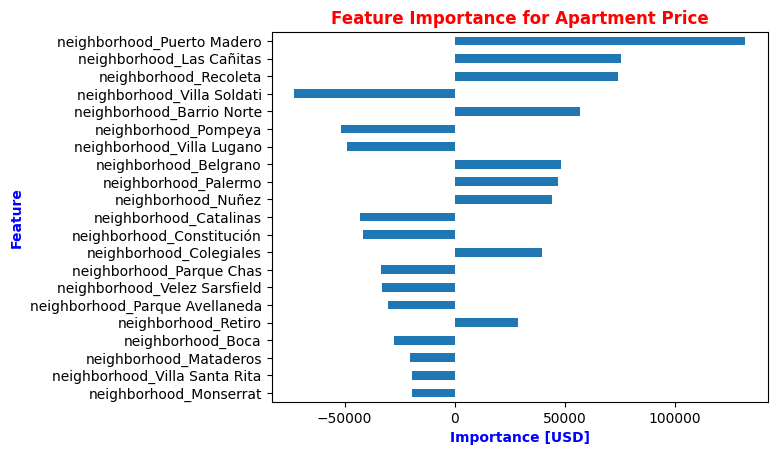

In [48]:
feat_imp.sort_values(key=abs).tail(21).plot(kind='barh')
plt.xlabel('Importance [USD]',color='blue',fontweight='bold')
plt.ylabel('Feature',color='blue',fontweight='bold')
plt.title('Feature Importance for Apartment Price',color='red',fontweight='bold')

 poshest neighborhoods in Buenos Aires like Puerto Madero and Recoleta increase the predicted price of an apartment, while more working-class neighborhoods like Villa Soldati and Villa Lugano decrease the predicted price.